# Implicit Game Recommendation on Steam
**CSE 158/258 Assignment 2** · Leo Weng, Shivam Sharma, Noah Weiss, Jeremy Su


## 1. Predictive task

**Task.** Given the set of games a Steam user has played, predict which *unplayed* games they are most likely to play next. Steam libraries contain no star ratings, so this is an **implicit-feedback, top-K recommendation** problem: we observe positives (games a user played) but no explicit negatives.

**Evaluation.** For every user we hold out one played game for validation and one for testing. A model produces a score for every candidate game; we measure where the held-out game lands in the ranked list using:
- **HR@10 (hit rate):** was the held-out game in the top 10?
- **NDCG@10:** like HR@10, but a hit at rank 1 counts more than a hit at rank 10 ($1/\log_2(\text{rank}+2)$).

These match how a recommender is actually used (a short list of suggestions) better than an all-pairs metric like AUC, which rewards correctly ordering games deep in the list that a user would never see.

**Baselines.**
- *Most Popular* (no personalization): the bar every personalized model has to clear.
- *Item-item similarity* (Jaccard, Cosine): the neighborhood models from class.
- *Latent-factor models:* BPR and ALS/WRMF, with and without playtime as a confidence signal.

**Validity checks.** We (i) compare sampled vs. full-ranking evaluation and fix tie handling, (ii) use harder popularity-sampled negatives, (iii) tune hyperparameters on a separate validation split and touch the test set once, (iv) report 95% bootstrap confidence intervals, and (v) run an ablation that separates the effect of playtime from the effect of confidence scale (Section 4).

## 2. Dataset: context, exploratory analysis and preprocessing

### 2.1 Context
We use the **Steam Australian user–items** dataset from Julian McAuley's UCSD recommender-systems repository (`australian_users_items.json.gz`). It was crawled from public Steam profiles of members of an Australian Steam community, and was introduced for bundle recommendation by Pathak, Gupta & McAuley (SIGIR 2017). Each line is one user, with a list of owned games and for each game:
- `item_id`, `item_name`
- `playtime_forever`: total minutes played
- `playtime_2weeks`: minutes in the last two weeks (not used here)

There are **no timestamps and no ratings**, which shapes both the task (implicit feedback) and the split (random leave-one-out rather than chronological).

### 2.2 Loading
Each line is a Python dict literal (single quotes), not strict JSON, so we parse it with `ast.literal_eval`.

In [1]:
import ast
import gzip
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix
from implicit.bpr import BayesianPersonalizedRanking
from implicit.als import AlternatingLeastSquares
from implicit.nearest_neighbours import CosineRecommender

# Reproducibility
SEED = 42
np.random.seed(SEED)

In [2]:
DATA_PATH = "australian_users_items.json.gz"

rows = []
with gzip.open(DATA_PATH, "rt", encoding="utf-8") as f:
    for line in f:
        user_obj = ast.literal_eval(line)
        u_id = user_obj["user_id"]
        for item in user_obj["items"]:
            rows.append((
                u_id,
                item["item_id"],
                item["item_name"],
                item["playtime_forever"]
            ))

df_raw = pd.DataFrame(rows, columns=["user_id", "item_id", "item_name", "playtime_forever"])
df_raw = (
    df_raw.sort_values("playtime_forever", ascending=False)
    .drop_duplicates(subset=["user_id", "item_id"], keep="first")
)
item_names = df_raw.drop_duplicates("item_id").set_index("item_id")["item_name"].to_dict()

total_owned = len(df_raw)
zero_playtime = (df_raw["playtime_forever"] == 0).sum()

print(f"Total owned (user, game) pairs : {total_owned:,}")
print(f"Unique users                   : {df_raw['user_id'].nunique():,}")
print(f"Unique games                   : {df_raw['item_id'].nunique():,}")
print(f"Unplayed backlog (0 mins)      : {zero_playtime:,} ({zero_playtime / total_owned:.1%})")

Total owned (user, game) pairs : 5,094,082
Unique users                   : 70,912
Unique games                   : 10,978
Unplayed backlog (0 mins)      : 1,847,730 (36.3%)


Some users list the same game more than once, so we keep the row with the highest playtime per (user, game) pair. **36.3% of owned games have never been played**, which matters for how we define positives (Section 2.4).

### 2.3 Exploratory analysis

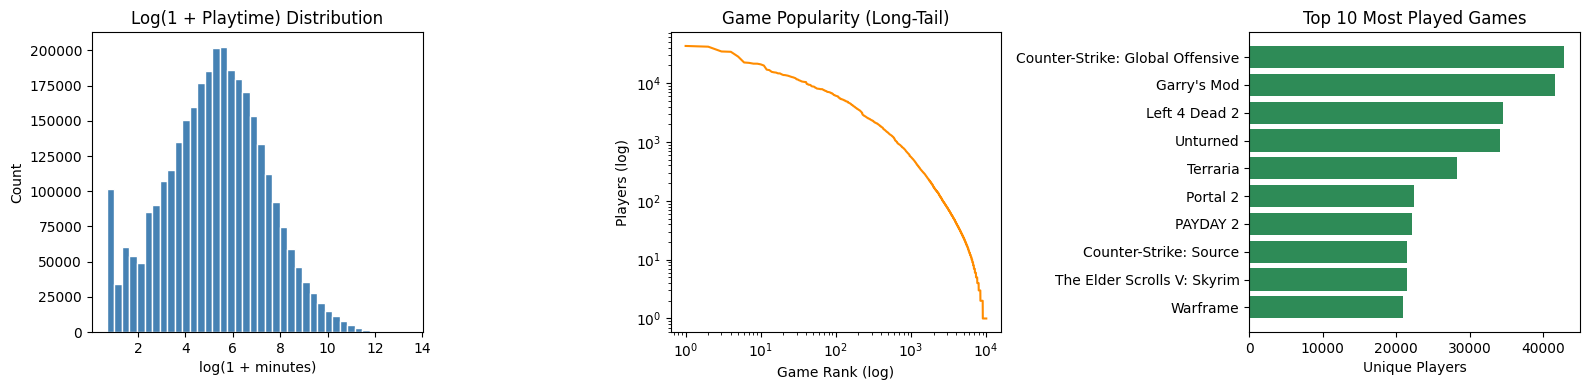

In [3]:
df_played = df_raw[df_raw["playtime_forever"] > 0].copy()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# 1. Log-playtime distribution
axes[0].hist(np.log1p(df_played["playtime_forever"]), bins=40, color="steelblue", edgecolor="white")
axes[0].set_title("Log(1 + Playtime) Distribution")
axes[0].set_xlabel("log(1 + minutes)")
axes[0].set_ylabel("Count")

# 2. Item popularity long-tail (log-log)
item_counts = df_played["item_id"].value_counts().values
axes[1].loglog(range(1, len(item_counts) + 1), item_counts, color="darkorange")
axes[1].set_title("Game Popularity (Long-Tail)")
axes[1].set_xlabel("Game Rank (log)")
axes[1].set_ylabel("Players (log)")

# 3. Top 10 most played games
top_games = df_played["item_name"].value_counts().head(10)[::-1]
axes[2].barh(top_games.index, top_games.values, color="seagreen")
axes[2].set_title("Top 10 Most Played Games")
axes[2].set_xlabel("Unique Players")

plt.tight_layout()
plt.show()

- **Playtime is heavy-tailed.** On a log scale it looks roughly bell-shaped: the median played game has about 3.4 hours, but the top 1% of (user, game) pairs exceed 400 hours. This motivates using $\log(1+\text{playtime})$ rather than raw minutes as a signal.
- **Popularity is long-tailed.** The roughly 100 most-played games (the top 1%) account for about 35% of all play interactions, while thousands of games have fewer than 5 players. Any recommender has to beat simply recommending the head of this curve.
- **The head is dominated by free-to-play and Valve titles** (Counter-Strike: GO, Garry's Mod, Left 4 Dead 2), which many users get from bundles or for free. This is part of why "owned" is a weak signal of "liked".

,mean,std,min,25%,50%,75%,99%,max
Owned games / user,71.8,132.4,1.0,14.0,40.0,87.0,480.0,7762.0
Played games / user,47.5,68.1,1.0,11.0,29.0,62.0,265.0,3475.0
Players / game,323.0,1447.7,1.0,5.0,23.0,112.0,6055.6,42837.0


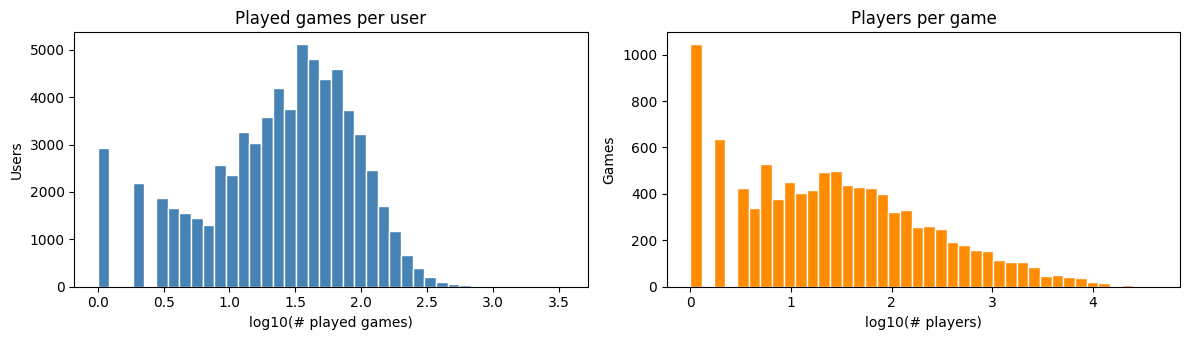

In [4]:
# Library sizes: how much data do we have per user and per game?
owned_per_user  = df_raw.groupby("user_id").size()
played_per_user = df_played.groupby("user_id").size()
players_per_game = df_played["item_id"].value_counts()

summary = pd.DataFrame({
    "Owned games / user":  owned_per_user.describe(percentiles=[.25, .5, .75, .99]),
    "Played games / user": played_per_user.describe(percentiles=[.25, .5, .75, .99]),
    "Players / game":      players_per_game.describe(percentiles=[.25, .5, .75, .99]),
}).T.drop(columns="count").round(1)
display(summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(np.log10(played_per_user), bins=40, color="steelblue", edgecolor="white")
axes[0].set_xlabel("log10(# played games)"); axes[0].set_ylabel("Users"); axes[0].set_title("Played games per user")
axes[1].hist(np.log10(players_per_game), bins=40, color="darkorange", edgecolor="white")
axes[1].set_xlabel("log10(# players)"); axes[1].set_ylabel("Games"); axes[1].set_title("Players per game")
plt.tight_layout(); plt.show()

The median user owns 40 games and has played 29, but a few collectors own thousands. The median game has 23 players. Both distributions are very skewed, so we filter out the sparsest users and games before modeling.

### 2.4 Preprocessing and train / validation / test split

1. **Positives = played games** (`playtime_forever > 0`). Owned-but-never-played games often come from bundles or sales and say little about preference.
2. **5-core filtering:** repeatedly drop users with fewer than 5 played games and games with fewer than 5 players, until stable. Collaborative filtering cannot learn anything useful about users or games with almost no interactions.
3. IDs are mapped to contiguous integers for the sparse matrices.

In [5]:
def k_core_filter(df, min_user=5, min_item=5):
    df = df.copy()
    while True:
        u_counts = df["user_id"].value_counts()
        i_counts = df["item_id"].value_counts()
        valid_u = u_counts[u_counts >= min_user].index
        valid_i = i_counts[i_counts >= min_item].index
        new_df = df[df["user_id"].isin(valid_u) & df["item_id"].isin(valid_i)]
        if len(new_df) == len(df):
            return new_df
        df = new_df

df_clean = k_core_filter(df_played, min_user=5, min_item=5)

# Map IDs to contiguous integers
user2idx = {u: idx for idx, u in enumerate(df_clean["user_id"].unique())}
item2idx = {i: idx for idx, i in enumerate(df_clean["item_id"].unique())}
idx2item = {idx: i for i, idx in item2idx.items()}

df_clean["u_idx"] = df_clean["user_id"].map(user2idx)
df_clean["i_idx"] = df_clean["item_id"].map(item2idx)

n_users = len(user2idx)
n_items = len(item2idx)
print(f"After 5-core filtering: {n_users:,} users, {n_items:,} games, {len(df_clean):,} interactions")
print(f"Matrix sparsity: {1 - len(df_clean) / (n_users * n_items):.4%}")

After 5-core filtering: 59,746 users, 7,603 games, 3,221,831 interactions
Matrix sparsity: 99.2907%


After filtering we keep **59,746 users, 7,603 games and 3.22M interactions** (99.29% sparse).

**Split.** There are no timestamps, so we use a random **leave-one-out** split: for each user, one played game goes to test, one to validation, and the rest to training.

In [6]:
# Leave-One-Out split per user (1 Val, 1 Test, rest Train)
df_shuffled = df_clean.sample(frac=1, random_state=SEED)
df_shuffled["rank"] = df_shuffled.groupby("u_idx").cumcount()

test_df  = df_shuffled[df_shuffled["rank"] == 0]
val_df   = df_shuffled[df_shuffled["rank"] == 1]
train_df = df_shuffled[df_shuffled["rank"] >= 2]

**Training matrices.** We build two user × game matrices from the training split:
- a **binary** matrix (1 = played), used by Most Popular, Jaccard, Cosine, BPR and binary ALS;
- a **playtime-weighted** matrix with confidence $c_{ui} = 1 + \alpha\log(1+\text{playtime}_{ui})$, used by weighted ALS. The log compresses extreme playtimes (idle/AFK hours, 8,000-hour Garry's Mod players).

In [7]:
# Build sparse User x Item matrices
# 1. Binary matrix (for Popularity, Cosine, BPR, Binary ALS)
train_binary = csr_matrix(
    (np.ones(len(train_df), dtype=np.float32), (train_df["u_idx"], train_df["i_idx"])),
    shape=(n_users, n_items)
)

# 2. Playtime-weighted matrix: c_ui = 1 + alpha * log(1 + playtime)
ALPHA = 2.0
weights = 1.0 + ALPHA * np.log1p(train_df["playtime_forever"].values).astype(np.float32)
train_weighted = csr_matrix(
    (weights, (train_df["u_idx"], train_df["i_idx"])),
    shape=(n_users, n_items)
)

## 3. Modeling

**ML formulation.** Input: a user $u$ and their set of played training games. Output: a score $s(u, i)$ for every game $i$; recommendations are the top-10 highest-scoring games the user hasn't played. 

We use the `implicit` library's implementations of Cosine, BPR and ALS, and implement Most Popular and Jaccard directly.

### 3.1 Evaluation harness (used by every model)
To compare models fairly, every model is scored on **the same candidates**: for 5,000 sampled test users, the held-out game plus 99 randomly sampled games the user never played. This is the standard "1 positive + 99 negatives" protocol. In Section 4 we show it has problems and replace it with full ranking.

In [8]:
# Build user -> set of all played items (to avoid sampling true positives as negatives)
user_all_items = df_clean.groupby("u_idx")["i_idx"].apply(set).to_dict()

def build_eval_candidates(eval_df, n_neg=99, max_users=5000):
    sample_df = eval_df.sample(n=min(max_users, len(eval_df)), random_state=SEED)
    candidates = {}
    for u, pos_i in zip(sample_df["u_idx"], sample_df["i_idx"]):
        seen = user_all_items[u]
        negs = []
        while len(negs) < n_neg:
            cand = np.random.randint(0, n_items)
            if cand not in seen:
                negs.append(cand)
        candidates[u] = np.array([pos_i] + negs, dtype=np.int32)
    return candidates

val_candidates  = build_eval_candidates(val_df,  n_neg=99, max_users=5000)
test_candidates = build_eval_candidates(test_df, n_neg=99, max_users=5000)

def evaluate_ranking(score_fn, candidates, k=10):
    hits, ndcgs = [], []
    for u, items in candidates.items():
        scores = score_fn(u, items)
        rank = (scores > scores[0]).sum()
        if rank < k:
            hits.append(1.0)
            ndcgs.append(1.0 / np.log2(rank + 2))
        else:
            hits.append(0.0)
            ndcgs.append(0.0)
    return np.mean(hits), np.mean(ndcgs)

### 3.2 Most Popular baseline
Score every game by how many training users played it.

In [9]:
results = []

item_pop = np.asarray(train_binary.sum(axis=0)).ravel()
pop_hr, pop_ndcg = evaluate_ranking(lambda u, items: item_pop[items], test_candidates)
results.append({"Model": "Most Popular", "Test HR@10": pop_hr, "Test NDCG@10": pop_ndcg})

### 3.3 Item-item Jaccard (course baseline)
$\text{score}(u,i) = \sum_{j \in I_u} \frac{|U_i \cap U_j|}{|U_i \cup U_j|}$, computed from the item co-occurrence matrix $X^\top X$.

In [10]:
# 2. Item-Item Jaccard (Course Baseline) ---
item_deg = np.asarray(train_binary.sum(axis=0)).ravel().astype(np.float32)
cooc = (train_binary.T @ train_binary).tocsr()

def score_jaccard(u, items):
    u_items = train_binary[u].indices
    if len(u_items) == 0:
        return np.zeros(len(items), dtype=np.float32)
    inter = cooc[u_items][:, items].toarray().astype(np.float32)
    union = item_deg[u_items][:, None] + item_deg[items][None, :] - inter
    jacc = np.divide(inter, union, out=np.zeros_like(inter), where=union > 0)
    return jacc.sum(axis=0)

jacc_hr, jacc_ndcg = evaluate_ranking(score_jaccard, test_candidates)
results.append({"Model": "Item-Item Jaccard", "Test HR@10": jacc_hr, "Test NDCG@10": jacc_ndcg})

### 3.4 Item-item Cosine
Keeping only each game's top $K=50$ neighbors. Unlike Jaccard, the denominator doesn't blow up when a niche game is compared with a mega-hit.

In [11]:
# 3. Item-Item Cosine Similarity (Course Baseline)
cos_model = CosineRecommender(K=50)
cos_model.fit(train_binary)

def score_cosine(u, items):
    # Compute dot product between user's train vector and candidate item similarity columns
    user_vec = train_binary[u]
    return np.asarray(user_vec.dot(cos_model.similarity[:, items]).toarray()).ravel()

cos_hr, cos_ndcg = evaluate_ranking(score_cosine, test_candidates)
results.append({"Model": "Item-Item Cosine", "Test HR@10": cos_hr, "Test NDCG@10": cos_ndcg})

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/implicit/utils.py:164: ParameterWarning: Method expects CSR input, and was passed coo_matrix instead. Converting to CSR took 0.019603967666625977 seconds
  warnings.warn(


  0%|          | 0/7603 [00:00<?, ?it/s]

### 3.5 Bayesian Personalized Ranking (BPR)
Learns user and game embeddings so that each user's played games score above randomly sampled unplayed ones (Rendle et al., 2009). Trained on the binary matrix with SGD.

In [12]:
# 4. BPR (Bayesian Personalized Ranking)
bpr_model = BayesianPersonalizedRanking(factors=64, regularization=0.01, iterations=100, random_state=SEED)
bpr_model.fit(train_binary)

def score_mf(model):
    return lambda u, items: model.item_factors[items] @ model.user_factors[u]

bpr_hr, bpr_ndcg = evaluate_ranking(score_mf(bpr_model), test_candidates)
results.append({"Model": "BPR (Binary)", "Test HR@10": bpr_hr, "Test NDCG@10": bpr_ndcg})

  0%|          | 0/100 [00:00<?, ?it/s]

### 3.6 ALS on binary feedback
Weighted matrix factorization (Hu, Koren & Volinsky, 2008) with confidence 1 for every played game. This is the "no playtime" version of our main model.

In [13]:
# 5. Binary ALS (Ablation Baseline)
als_bin = AlternatingLeastSquares(factors=64, regularization=0.1, iterations=20, random_state=SEED)
als_bin.fit(train_binary)
als_b_hr, als_b_ndcg = evaluate_ranking(score_mf(als_bin), test_candidates)
results.append({"Model": "ALS (Binary)", "Test HR@10": als_b_hr, "Test NDCG@10": als_b_ndcg})

  0%|          | 0/20 [00:00<?, ?it/s]

### 3.7 ALS with log-playtime confidence (main model)
Same model, but played games get confidence $c_{ui} = 1 + 2\log(1+\text{playtime})$, so a 400-hour favorite counts more than a 10-minute trial.

In [14]:
# 6. Playtime-Weighted ALS (Main Model)
als_wt = AlternatingLeastSquares(factors=64, regularization=0.1, iterations=20, random_state=SEED)
als_wt.fit(train_weighted)
als_w_hr, als_w_ndcg = evaluate_ranking(score_mf(als_wt), test_candidates)
results.append({"Model": "ALS (Log-Playtime Weighted)", "Test HR@10": als_w_hr, "Test NDCG@10": als_w_ndcg})

  0%|          | 0/20 [00:00<?, ?it/s]

### 3.8 Initial results (sampled evaluation)

In [15]:
results_df = pd.DataFrame(results)
display(results_df.round(4))

,Model,Test HR@10,Test NDCG@10
0,Most Popular,0.8528,0.6107
1,Item-Item Jaccard,0.8840,0.6613
2,Item-Item Cosine,0.9554,0.7168
3,BPR (Binary),0.7762,0.5547
4,ALS (Binary),0.7710,0.5556
5,ALS (Log-Playtime Weighted),0.8826,0.6911


Taken at face value, this table says Cosine is best (HR@10 0.955), playtime weighting adds about 11 points over binary ALS, and BPR is worse than Most Popular. **Section 4 shows that the first two conclusions don't hold up**, because of how this evaluation protocol works.

## 4. Evaluation

### 4.1 Is the sampled protocol trustworthy?
We check three things about the protocol above:
1. **Ties.** `evaluate_ranking` uses `rank = (scores > scores[0]).sum()`, so if the held-out game ties with negatives (e.g. everything scores 0) it is placed *ahead* of all of them. We use the **expected rank under random tie-breaking**: `#greater + 0.5 × #tied`.
2. **Easy negatives.** Uniformly sampled negatives are mostly obscure games nobody plays, so they're easy to rank below anything popular. We add **popularity-sampled negatives**, drawn in proportion to how many users play each game.
3. **Sampled vs. full ranking.** Sampled metrics can disagree with the full-ranking metrics they approximate and can even reorder models (Krichene & Rendle, KDD 2020). We add **full-ranking** HR@10 / NDCG@10: the held-out game is ranked against *every* game the user hasn't played (training games and the other held-out game are masked). This is what a deployed recommender actually faces, so it is our **primary metric** from here on.

All protocols use the same 5,000 test users.

In [16]:
import warnings
warnings.filterwarnings("ignore", message="Method expects CSR input")

# ---------- Shared evaluation utilities ----------
def metrics_from_ranks(ranks, k=10):
    hit = ranks < k
    ndcg = np.where(hit, 1.0 / np.log2(ranks + 2), 0.0)
    return hit.mean(), ndcg.mean()

def bootstrap_ci(ranks, k=10, n_boot=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    hit = (ranks < k).astype(float)
    ndcg = np.where(ranks < k, 1.0 / np.log2(ranks + 2), 0.0)
    idx = rng.integers(0, len(ranks), size=(n_boot, len(ranks)))
    hr_b, nd_b = hit[idx].mean(1), ndcg[idx].mean(1)
    return np.percentile(hr_b, [2.5, 97.5]), np.percentile(nd_b, [2.5, 97.5])

def sampled_ranks(score_fn, candidates, tie_aware=True):
    ranks = []
    for u, items in candidates.items():
        s = np.asarray(score_fn(u, items), dtype=np.float64)
        greater = (s[1:] > s[0]).sum()
        ties = (s[1:] == s[0]).sum() if tie_aware else 0
        ranks.append(greater + 0.5 * ties)
    return np.array(ranks)

test_item_of = test_df.set_index("u_idx")["i_idx"]
val_item_of  = val_df.set_index("u_idx")["i_idx"]
test_users = np.array(list(test_candidates.keys()))
val_users  = np.array(list(val_candidates.keys()))

def full_ranks(score_batch_fn, users, target_of, exclude_of, batch=1000):
    out = []
    for start in range(0, len(users), batch):
        ub = users[start:start + batch]
        S = np.array(score_batch_fn(ub), dtype=np.float64)
        rows = np.arange(len(ub))
        r, c = train_binary[ub].nonzero()
        S[r, c] = -np.inf                                   
        S[rows, exclude_of.loc[ub].values] = -np.inf         
        tgt = target_of.loc[ub].values
        st = S[rows, tgt][:, None]
        greater = (S > st).sum(1)
        ties = (S == st).sum(1) - 1                          
        out.append(greater + 0.5 * ties)
    return np.concatenate(out)

def full_test(fn):  return full_ranks(fn, test_users, test_item_of, val_item_of)
def full_val(fn):   return full_ranks(fn, val_users,  val_item_of,  test_item_of)

# ---------- Popularity-sampled negatives (harder candidates) ----------
pop_p = item_pop / item_pop.sum()
def build_pop_candidates(target_of, users, n_neg=99, seed=SEED):
    rng = np.random.default_rng(seed)
    cands = {}
    for u in users:
        seen, negs = user_all_items[u], []
        while len(negs) < n_neg:
            for x in rng.choice(n_items, size=4 * n_neg, p=pop_p):
                if x not in seen and x not in negs:
                    negs.append(x)
                    if len(negs) == n_neg:
                        break
        cands[u] = np.array([target_of[u]] + negs, dtype=np.int32)
    return cands

test_pop_candidates = build_pop_candidates(test_item_of, test_users)

# ---------- Batch (all-items) scoring functions for each model ----------
cooc_d = cooc.toarray().astype(np.float32)
union_d = item_deg[:, None] + item_deg[None, :] - cooc_d
J = np.divide(cooc_d, union_d, out=np.zeros_like(cooc_d), where=union_d > 0)
del cooc_d, union_d

def batch_pop(ub):          return np.tile(item_pop.astype(np.float64), (len(ub), 1))
def batch_jaccard(ub):      return train_binary[ub] @ J
def batch_itemknn(model):   return lambda ub: (train_binary[ub] @ model.similarity).toarray()
def batch_mf(model):        return lambda ub: model.user_factors[ub] @ model.item_factors.T

In [17]:
# ---------- Re-evaluate the six models under each protocol ----------
models_v1 = {
    "Most Popular":                (lambda u, items: item_pop[items],            batch_pop),
    "Item-Item Jaccard":           (score_jaccard,                                batch_jaccard),
    "Item-Item Cosine (K=50)":     (score_cosine,                                 batch_itemknn(cos_model)),
    "BPR (Binary)":                (score_mf(bpr_model),                          batch_mf(bpr_model)),
    "ALS (Binary)":                (score_mf(als_bin),                            batch_mf(als_bin)),
    "ALS (Log-Playtime Weighted)": (score_mf(als_wt),                             batch_mf(als_wt)),
}

protocol_rows = []
for name, (fn, bfn) in models_v1.items():
    row = {"Model": name}
    row["Uniform-99 HR (orig., ties=hit)"] = metrics_from_ranks(sampled_ranks(fn, test_candidates, tie_aware=False))[0]
    row["Uniform-99 HR (tie-aware)"]       = metrics_from_ranks(sampled_ranks(fn, test_candidates))[0]
    row["Popularity-99 HR"]                = metrics_from_ranks(sampled_ranks(fn, test_pop_candidates))[0]
    hr, nd = metrics_from_ranks(full_test(bfn))
    row["Full-rank HR@10"], row["Full-rank NDCG@10"] = hr, nd
    protocol_rows.append(row)

protocol_df = pd.DataFrame(protocol_rows).set_index("Model")
display(protocol_df.style.format("{:.4f}").background_gradient(axis=0, cmap="Greens"))

zero_frac = np.mean([score_cosine(u, items)[0] == 0 for u, items in test_candidates.items()])
print(f"Cosine (K=50): held-out game scores exactly 0 for {zero_frac:.1%} of test users "
      "-> under the original rank rule these all count as ties won by the positive")

,"Uniform-99 HR (orig., ties=hit)",Uniform-99 HR (tie-aware),Popularity-99 HR,Full-rank HR@10,Full-rank NDCG@10
Model,,,,,
Most Popular,0.8528,0.8528,0.2706,0.1922,0.1172
Item-Item Jaccard,0.8840,0.8840,0.3472,0.2350,0.1452
Item-Item Cosine (K=50),0.9554,0.7844,0.3342,0.2212,0.1376
BPR (Binary),0.7762,0.7762,0.5694,0.1944,0.1225
ALS (Binary),0.7710,0.7710,0.3584,0.1662,0.1013
ALS (Log-Playtime Weighted),0.8826,0.8826,0.4880,0.2672,0.1560


Cosine (K=50): held-out game scores exactly 0 for 20.4% of test users -> under the original rank rule these all count as ties won by the positive


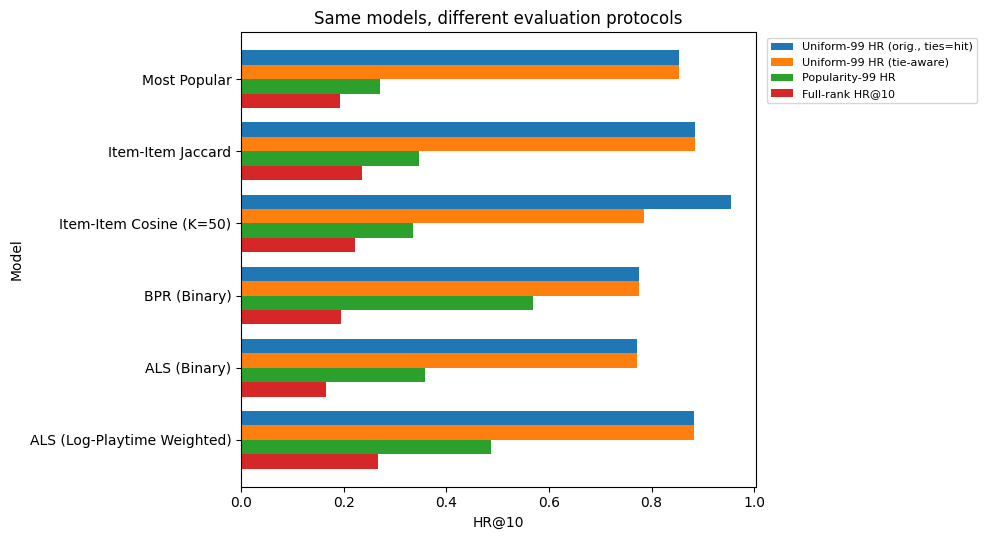

In [18]:
ax = protocol_df[["Uniform-99 HR (orig., ties=hit)", "Uniform-99 HR (tie-aware)",
                  "Popularity-99 HR", "Full-rank HR@10"]].plot.barh(figsize=(10, 5.5), width=0.8)
ax.set_xlabel("HR@10")
ax.set_title("Same models, different evaluation protocols")
ax.invert_yaxis()
ax.legend(fontsize=8, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Takeaways**
- **Cosine's win was a tie artifact.** For 20.4% of test users the held-out game gets an exact 0 score from Cosine (K=50), because it isn't in the top-50 neighbor list of any game the user played. The original rule counts each of these ties as a win. With ties broken fairly, Cosine's HR@10 drops from **0.955 to 0.784**, below Most Popular (0.853).
- **Uniform negatives are too easy.** Most Popular gets 0.853 HR@10 without any personalization. With popularity-sampled negatives it falls to 0.271.
- **Protocols reorder models.** BPR is near last on uniform negatives (0.776) but **first** on popularity-sampled negatives (0.569). Under full ranking, log-playtime ALS is best (HR@10 0.267) and binary ALS is last (0.166).
- Full-ranking numbers are much lower (≈0.17–0.27) because the held-out game competes with ~7,500 games instead of 99. That's expected, and it's the honest number.

### 4.2 Does playtime help, or just the confidence scale?
In ALS, every unplayed pair has confidence 1. Binary ALS also gives played games confidence 1, so a played game counts no more than any of the ~7,600 unplayed ones. Log-playtime ALS gives played games ≈11.5 on average. Comparing the two mixes up two effects: played games getting **more weight overall**, and that weight **depending on playtime**.

Two controls separate them (same factors, regularization and iterations):
- **Constant confidence:** every played game gets the *mean* playtime weight (same scale, no playtime information).
- **Shuffled playtime:** the playtime weights are randomly permuted across played games (same distribution, attached to the wrong games).

If playtime carries signal, log-playtime ALS should beat **both** controls.

In [19]:
rng = np.random.default_rng(SEED)
mean_w = weights.mean()
train_const = csr_matrix((np.full(len(train_df), mean_w, dtype=np.float32),
                          (train_df["u_idx"], train_df["i_idx"])), shape=(n_users, n_items))
train_shuffled = csr_matrix((rng.permutation(weights).astype(np.float32),
                             (train_df["u_idx"], train_df["i_idx"])), shape=(n_users, n_items))

def fit_als(mat, factors=64, reg=0.1, iters=20):
    m = AlternatingLeastSquares(factors=factors, regularization=reg, iterations=iters, random_state=SEED)
    m.fit(mat, show_progress=False)
    return m

als_const = fit_als(train_const)
als_shuf  = fit_als(train_shuffled)

ablation_rows = []
for name, m in [("ALS binary (c = 1)", als_bin),
                (f"ALS constant confidence (c = {mean_w:.2f})", als_const),
                ("ALS shuffled playtime weights", als_shuf),
                ("ALS log-playtime weights", als_wt)]:
    r = full_test(batch_mf(m))
    hr, nd = metrics_from_ranks(r)
    (hr_lo, hr_hi), (nd_lo, nd_hi) = bootstrap_ci(r)
    ablation_rows.append({"Model": name, "Full-rank HR@10": hr, "HR 95% CI": f"[{hr_lo:.4f}, {hr_hi:.4f}]",
                          "Full-rank NDCG@10": nd, "NDCG 95% CI": f"[{nd_lo:.4f}, {nd_hi:.4f}]"})
ablation_df = pd.DataFrame(ablation_rows).set_index("Model")
display(ablation_df.style.format({"Full-rank HR@10": "{:.4f}", "Full-rank NDCG@10": "{:.4f}"}))

,Full-rank HR@10,HR 95% CI,Full-rank NDCG@10,NDCG 95% CI
Model,,,,
ALS binary (c = 1),0.1662,"[0.1560, 0.1766]",0.1013,"[0.0943, 0.1084]"
ALS constant confidence (c = 11.48),0.2764,"[0.2648, 0.2894]",0.1596,"[0.1515, 0.1675]"
ALS shuffled playtime weights,0.2730,"[0.2606, 0.2852]",0.1575,"[0.1492, 0.1660]"
ALS log-playtime weights,0.2672,"[0.2550, 0.2792]",0.1560,"[0.1480, 0.1640]"


**Takeaways**
- Binary → log-playtime improves full HR@10 from 0.166 to 0.267, but **constant confidence (0.276) and shuffled weights (0.273) do just as well**, and all three 95% CIs overlap.
- So the gain comes from **weighting played games more heavily than unplayed ones**, not from *how long* each game was played. Raw `playtime_forever` adds little beyond "the user played it". A plausible reason is that lifetime playtime mixes up enjoyment with game length and genre (an MMO naturally racks up more hours than a 6-hour story game) and idle/AFK time.

### 4.3 Hyperparameter tuning on the validation set
So far every model used hand-picked hyperparameters. We tune each one by **full-ranking NDCG@10 on 5,000 validation users** (the validation game, never the test game), then evaluate on test once:
- **Cosine:** neighborhood size $K$
- **Log-playtime ALS:** confidence scale $\alpha$, then latent factors × regularization $\lambda$
- **Constant-confidence ALS:** the same factors × $\lambda$ grid, so the comparison stays fair
- **BPR:** learning rate

In [20]:
import time
def val_ndcg(bfn):
    return metrics_from_ranks(full_val(bfn))[1]

# --- Item-Item Cosine: neighborhood size K ---
cos_K_grid = [3, 5, 10, 25, 50, 100, 200, 400]
cos_val = {}
for K in cos_K_grid:
    m = CosineRecommender(K=K); m.fit(train_binary, show_progress=False)
    cos_val[K] = val_ndcg(batch_itemknn(m))
best_K = max(cos_val, key=cos_val.get)
cos_val = {k: float(v) for k, v in cos_val.items()}
print("Cosine  val NDCG@10 by K:", {k: round(float(v), 4) for k, v in cos_val.items()}, "-> best K =", best_K)

# --- Playtime-weighted ALS: alpha ---
def weighted_matrix(alpha):
    w = 1.0 + alpha * np.log1p(train_df["playtime_forever"].values).astype(np.float32)
    return csr_matrix((w, (train_df["u_idx"], train_df["i_idx"])), shape=(n_users, n_items)), w.mean()

alpha_grid = [0.25, 0.5, 1, 2, 4, 8]
alpha_val = {}
for a in alpha_grid:
    mat, _ = weighted_matrix(a)
    alpha_val[a] = val_ndcg(batch_mf(fit_als(mat)))
best_alpha = max(alpha_val, key=alpha_val.get)
print("Wtd ALS val NDCG@10 by alpha:", {k: round(float(v), 4) for k, v in alpha_val.items()}, "-> best alpha =", best_alpha)

# --- Factors x regularization for weighted ALS and constant-confidence ALS ---
factor_grid, reg_grid = [16, 32, 64, 128], [0.1, 1.0, 10.0, 100.0]
best_wmat, best_wmean = weighted_matrix(best_alpha)
best_cmat = csr_matrix((np.full(len(train_df), best_wmean, dtype=np.float32),
                        (train_df["u_idx"], train_df["i_idx"])), shape=(n_users, n_items))
grid_w = pd.DataFrame(index=factor_grid, columns=reg_grid, dtype=float)
grid_c = pd.DataFrame(index=factor_grid, columns=reg_grid, dtype=float)
for f in factor_grid:
    for lam in reg_grid:
        grid_w.loc[f, lam] = val_ndcg(batch_mf(fit_als(best_wmat, factors=f, reg=lam)))
        grid_c.loc[f, lam] = val_ndcg(batch_mf(fit_als(best_cmat, factors=f, reg=lam)))
best_w_cfg = tuple(x.item() for x in grid_w.stack().idxmax()); best_c_cfg = tuple(x.item() for x in grid_c.stack().idxmax())
print("Wtd ALS best (factors, reg):", best_w_cfg, f"val NDCG={grid_w.stack().max():.4f}")
print("Const ALS best (factors, reg):", best_c_cfg, f"val NDCG={grid_c.stack().max():.4f}")

# --- BPR: learning rate ---
bpr_lr_grid = [0.003, 0.01, 0.05]
bpr_val, bpr_models = {}, {}
for lr in bpr_lr_grid:
    t0 = time.time()
    m = BayesianPersonalizedRanking(factors=64, learning_rate=lr, regularization=0.01,
                                    iterations=100, random_state=SEED)
    m.fit(train_binary, show_progress=False)
    bpr_val[lr], bpr_models[lr] = val_ndcg(batch_mf(m)), m
    print(f"  BPR lr={lr}: val NDCG@10={bpr_val[lr]:.4f} ({time.time() - t0:.0f}s)")
best_lr = max(bpr_val, key=bpr_val.get)
print("BPR best learning rate:", best_lr)

Cosine  val NDCG@10 by K: {3: 0.1714, 5: 0.1674, 10: 0.1598, 25: 0.1469, 50: 0.1461, 100: 0.1513, 200: 0.1551, 400: 0.1577} -> best K = 3
Wtd ALS val NDCG@10 by alpha: {0.25: 0.1221, 0.5: 0.1537, 1: 0.1665, 2: 0.163, 4: 0.1523, 8: 0.1338} -> best alpha = 1
Wtd ALS best (factors, reg): (64, 100.0) val NDCG=0.1770
Const ALS best (factors, reg): (64, 100.0) val NDCG=0.1838
  BPR lr=0.003: val NDCG@10=0.1420 (110s)
  BPR lr=0.01: val NDCG@10=0.1249 (126s)
  BPR lr=0.05: val NDCG@10=0.0787 (103s)
BPR best learning rate: 0.003


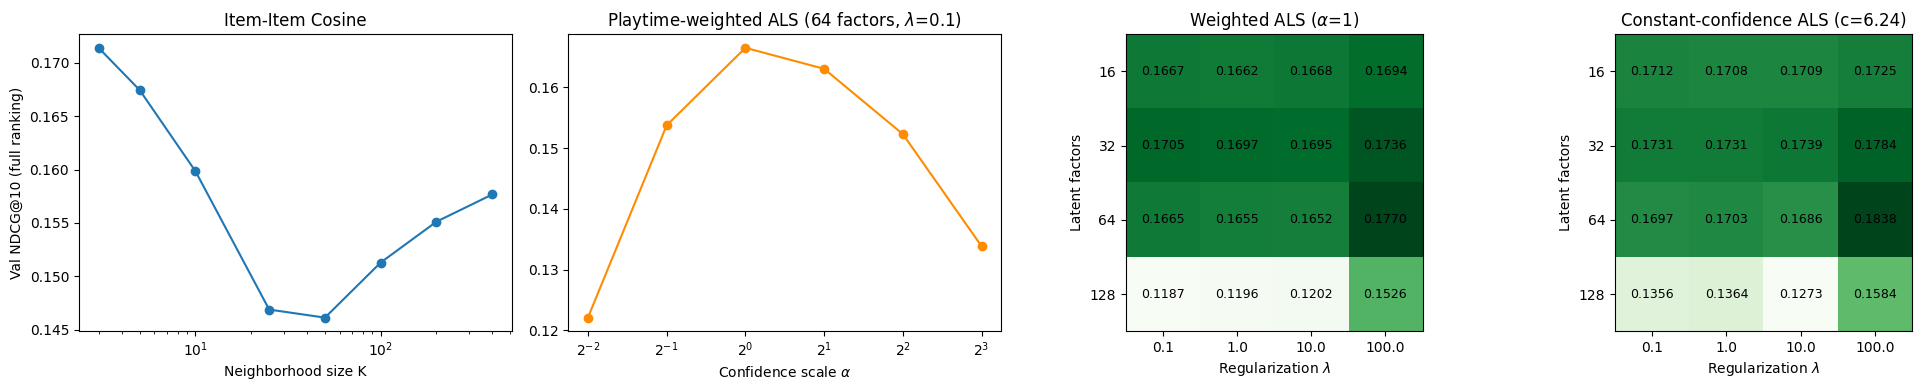

In [21]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))

axes[0].plot(cos_K_grid, [cos_val[k] for k in cos_K_grid], marker="o")
axes[0].set_xscale("log"); axes[0].set_xlabel("Neighborhood size K"); axes[0].set_ylabel("Val NDCG@10 (full ranking)")
axes[0].set_title("Item-Item Cosine")

axes[1].plot(alpha_grid, [alpha_val[a] for a in alpha_grid], marker="o", color="darkorange")
axes[1].set_xscale("log", base=2); axes[1].set_xlabel(r"Confidence scale $\alpha$")
axes[1].set_title("Playtime-weighted ALS (64 factors, $\\lambda$=0.1)")

for ax, grid, title in [(axes[2], grid_w, f"Weighted ALS ($\\alpha$={best_alpha})"),
                        (axes[3], grid_c, f"Constant-confidence ALS (c={best_wmean:.2f})")]:
    im = ax.imshow(grid.values.astype(float), cmap="Greens")
    ax.set_xticks(range(len(reg_grid)), [str(r) for r in reg_grid]); ax.set_xlabel(r"Regularization $\lambda$")
    ax.set_yticks(range(len(factor_grid)), factor_grid); ax.set_ylabel("Latent factors")
    for i in range(len(factor_grid)):
        for j in range(len(reg_grid)):
            ax.text(j, i, f"{grid.values[i, j]:.4f}", ha="center", va="center", fontsize=9)
    ax.set_title(title)
plt.tight_layout()
plt.show()

**Takeaways**
- **Cosine:** smaller neighborhoods are better, with validation NDCG rising steadily down to $K=3$. Keeping only each game's few strongest co-play neighbors filters out noise from mega-popular games.
- **Log-playtime ALS:** $\alpha=1$ is best. Larger $\alpha$ makes the model lean harder on playtime and hurts (NDCG falls from 0.167 at $\alpha=1$ to 0.134 at $\alpha=8$), consistent with the ablation.
- **Regularization:** both ALS variants do best with strong regularization ($\lambda=100$, vs. the 0.1 used in Section 3), so the original models were overfitting. 128 factors is clearly worse unless heavily regularized.
- **BPR:** the default learning rate (0.01) was too high; 0.003 is better.
- *Limitation:* some chosen values ($K=3$, $\lambda=100$, BPR lr $=0.003$) sit at the edge of the grid, so slightly better settings may exist beyond what we searched.

### 4.4 Final test results
Each model uses its tuned configuration and is evaluated **once** on the test users. Full-ranking metrics come with 95% bootstrap confidence intervals (1,000 resamples of users).

,Full HR@10,Full HR 95% CI,Full NDCG@10,Full NDCG 95% CI,Uniform-99 HR (tie-aware),Popularity-99 HR
Model,,,,,,
Most Popular,0.1922,"[0.182, 0.203]",0.1172,"[0.110, 0.125]",0.8528,0.2706
Item-Item Jaccard,0.2350,"[0.224, 0.247]",0.1452,"[0.137, 0.154]",0.8840,0.3472
Item-Item Cosine (K=3),0.2566,"[0.244, 0.269]",0.1645,"[0.156, 0.173]",0.3626,0.3508
BPR (lr=0.003),0.2314,"[0.220, 0.242]",0.1408,"[0.132, 0.149]",0.7826,0.4918
"ALS constant conf. (f=64, λ=100.0)",0.2900,"[0.277, 0.303]",0.1737,"[0.165, 0.182]",0.9112,0.4958
"ALS log-playtime (α=1, f=64, λ=100.0)",0.2822,"[0.269, 0.295]",0.1684,"[0.160, 0.177]",0.9088,0.4846


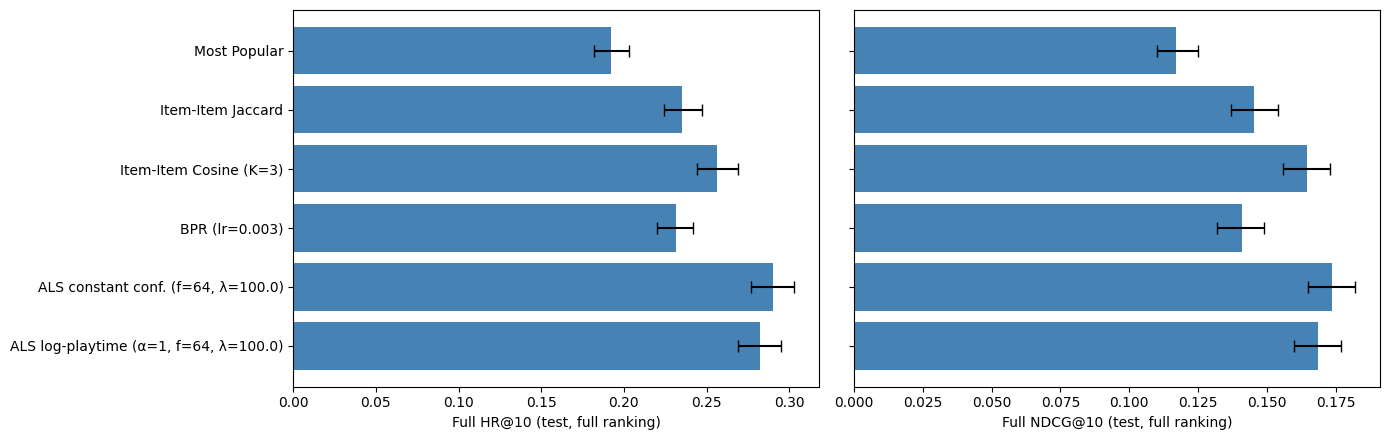

In [22]:
cos_best = CosineRecommender(K=best_K); cos_best.fit(train_binary, show_progress=False)
als_w_best = fit_als(best_wmat, factors=best_w_cfg[0], reg=best_w_cfg[1])
als_c_best = fit_als(best_cmat, factors=best_c_cfg[0], reg=best_c_cfg[1])
bpr_best = bpr_models[best_lr]

def score_itemknn(model):
    return lambda u, items: np.asarray(train_binary[u].dot(model.similarity[:, items]).toarray()).ravel()

final_models = {
    "Most Popular":                                   (lambda u, items: item_pop[items], batch_pop),
    "Item-Item Jaccard":                              (score_jaccard, batch_jaccard),
    f"Item-Item Cosine (K={best_K})":                 (score_itemknn(cos_best), batch_itemknn(cos_best)),
    f"BPR (lr={best_lr})":                            (score_mf(bpr_best), batch_mf(bpr_best)),
    f"ALS constant conf. (f={best_c_cfg[0]}, λ={best_c_cfg[1]})":               (score_mf(als_c_best), batch_mf(als_c_best)),
    f"ALS log-playtime (α={best_alpha}, f={best_w_cfg[0]}, λ={best_w_cfg[1]})":  (score_mf(als_w_best), batch_mf(als_w_best)),
}

final_rows, final_ranks = [], {}
for name, (fn, bfn) in final_models.items():
    r = full_test(bfn); final_ranks[name] = r
    hr, nd = metrics_from_ranks(r)
    (hr_lo, hr_hi), (nd_lo, nd_hi) = bootstrap_ci(r)
    s_hr, s_nd = metrics_from_ranks(sampled_ranks(fn, test_candidates))
    p_hr, p_nd = metrics_from_ranks(sampled_ranks(fn, test_pop_candidates))
    final_rows.append({"Model": name,
                       "Full HR@10": hr, "Full HR 95% CI": f"[{hr_lo:.3f}, {hr_hi:.3f}]",
                       "Full NDCG@10": nd, "Full NDCG 95% CI": f"[{nd_lo:.3f}, {nd_hi:.3f}]",
                       "Uniform-99 HR (tie-aware)": s_hr, "Popularity-99 HR": p_hr})
final_df = pd.DataFrame(final_rows).set_index("Model")
display(final_df.style.format({c: "{:.4f}" for c in final_df.columns if "CI" not in c}))

# Bar chart with CI error bars
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, col, ci_col in [(axes[0], "Full HR@10", "Full HR 95% CI"), (axes[1], "Full NDCG@10", "Full NDCG 95% CI")]:
    vals = final_df[col].values
    lo = np.array([float(s.strip("[]").split(",")[0]) for s in final_df[ci_col]])
    hi = np.array([float(s.strip("[]").split(",")[1]) for s in final_df[ci_col]])
    ax.barh(final_df.index, vals, xerr=[vals - lo, hi - vals], color="steelblue", capsize=4)
    ax.invert_yaxis(); ax.set_xlabel(col + " (test, full ranking)")
axes[1].set_yticklabels([])
plt.tight_layout()
plt.show()

**Takeaways**
- **Both ALS variants are the best models**: constant confidence reaches HR@10 0.290 / NDCG@10 0.174, and log-playtime 0.282 / 0.168. Their CIs overlap, so neither is clearly better.
- On HR@10, ALS beats tuned Cosine (0.257) with **non-overlapping** CIs. On NDCG@10 the gap is smaller (0.174 vs. 0.165) and the CIs touch.
- **Every personalized model clearly beats Most Popular** (0.192 / 0.117).
- **Tuning mattered.** BPR went from roughly Most Popular level (0.194 full HR@10 in 4.1) to 0.231, and Cosine's NDCG from 0.138 ($K=50$) to 0.165 ($K=3$).
- **Sampled metrics would have misled us again.** Tuned Cosine has the *lowest* tie-aware uniform-99 HR (0.363) but is third under full ranking: a smaller $K$ means more exact-zero scores, which the sampled protocol punishes even though it doesn't hurt the real top-10 list.

### 4.5 Who benefits? Performance by library size
We bucket test users into quartiles by the number of games in their training set.

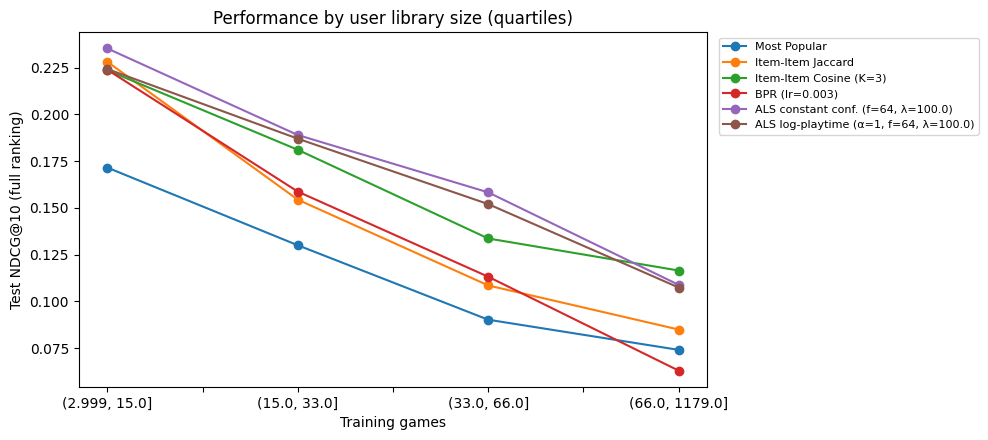

Model,Most Popular,Item-Item Jaccard,Item-Item Cosine (K=3),BPR (lr=0.003),"ALS constant conf. (f=64, λ=100.0)","ALS log-playtime (α=1, f=64, λ=100.0)"
Training games,,,,,,
"(2.999, 15.0]",0.1716,0.2282,0.2237,0.2239,0.2354,0.2243
"(15.0, 33.0]",0.1300,0.1544,0.1811,0.1587,0.1890,0.1870
"(33.0, 66.0]",0.0902,0.1085,0.1336,0.1132,0.1583,0.1520
"(66.0, 1179.0]",0.0740,0.0849,0.1165,0.0629,0.1088,0.1074


In [23]:
n_train_games = np.asarray(train_binary[test_users].sum(1)).ravel()
buckets = pd.qcut(n_train_games, q=4, labels=None, duplicates="drop")
bucket_rows = []
for name, r in final_ranks.items():
    for b in buckets.categories:
        mask = np.asarray(buckets == b)
        bucket_rows.append({"Model": name, "Training games": str(b), "Full NDCG@10": metrics_from_ranks(r[mask])[1]})
bucket_df = pd.DataFrame(bucket_rows).pivot(index="Training games", columns="Model", values="Full NDCG@10")
bucket_df = bucket_df.loc[[str(b) for b in buckets.categories], list(final_ranks.keys())]
ax = bucket_df.plot(marker="o", figsize=(10, 4.5))
ax.set_ylabel("Test NDCG@10 (full ranking)"); ax.set_title("Performance by user library size (quartiles)")
ax.legend(fontsize=8, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); plt.show()
display(bucket_df.style.format("{:.4f}"))

**Takeaways**
- **Every model gets worse as library size grows.** A user with 300 games has many more plausible held-out games, so finding the exact one in the top 10 is harder.
- **The advantage over popularity grows with activity.** For light users (≤15 games) the personalized models are only ~0.05 NDCG above Most Popular, and Jaccard, Cosine, BPR and both ALS variants are within ~0.01 of each other. For the heaviest quartile, Cosine (0.117) and ALS (≈0.109) are about 1.5× Most Popular (0.074), while BPR falls *below* it (0.063).
- **Different models win in different regimes.** ALS is best for light-to-mid users, while Cosine edges ahead for the heaviest users, whose large libraries give the neighborhood model more evidence to aggregate.

### 4.6 Qualitative examples
Below: one user the original (untuned) log-playtime ALS model misses, followed by the tuned constant-confidence ALS on the same user and on a user it gets right.

In [24]:
def inspect_user(u_idx, model, top_n=5):
    u_train = train_df[train_df["u_idx"] == u_idx].sort_values("playtime_forever", ascending=False)
    print(f"=== User {u_idx} | Top Played Games (Train) ===")
    for _, row in u_train.head(5).iterrows():
        print(f"  - {row['item_name']} ({row['playtime_forever'] / 60:.1f} hrs)")

    test_item = test_df[test_df["u_idx"] == u_idx]["item_id"].values[0]
    print(f"\nHeld-out Test Game: {item_names[test_item]}")

    rec_ids, rec_scores = model.recommend(u_idx, train_binary[u_idx], N=top_n, filter_already_liked_items=True)
    print(f"\nTop-{top_n} Recommended Games:")
    for rank, (i_idx, score) in enumerate(zip(rec_ids, rec_scores), 1):
        name = item_names[idx2item[i_idx]]
        hit_tag = "  <-- HIT!" if idx2item[i_idx] == test_item else ""
        print(f"  {rank}. {name} (score: {score:.3f}){hit_tag}")

inspect_user(u_idx=10, model=als_wt, top_n=5)

=== User 10 | Top Played Games (Train) ===
  - Garry's Mod (8213.5 hrs)
  - ARK: Survival Evolved (490.9 hrs)
  - Grand Theft Auto V (399.6 hrs)
  - METAL GEAR SOLID V: THE PHANTOM PAIN (339.0 hrs)
  - The Witcher 3: Wild Hunt (238.6 hrs)

Held-out Test Game: PlanetSide 2

Top-5 Recommended Games:
  1. Evolve Stage 2 (score: 1.231)
  2. Contagion (score: 1.216)
  3. Half-Life 2: Deathmatch (score: 1.092)
  4. Cry of Fear (score: 1.025)
  5. Dead Space (score: 1.023)


In [25]:
inspect_user(u_idx=10, model=als_c_best, top_n=5)
print()
hit_users = [u for u in test_users[:300]
             if test_item_of[u] in als_c_best.recommend(u, train_binary[u], N=5, filter_already_liked_items=True)[0]]
inspect_user(u_idx=hit_users[0], model=als_c_best, top_n=5)

=== User 10 | Top Played Games (Train) ===
  - Garry's Mod (8213.5 hrs)
  - ARK: Survival Evolved (490.9 hrs)
  - Grand Theft Auto V (399.6 hrs)
  - METAL GEAR SOLID V: THE PHANTOM PAIN (339.0 hrs)
  - The Witcher 3: Wild Hunt (238.6 hrs)

Held-out Test Game: PlanetSide 2

Top-5 Recommended Games:
  1. Evolve Stage 2 (score: 0.973)
  2. Half-Life 2: Deathmatch (score: 0.968)
  3. Metro 2033 (score: 0.893)
  4. Cry of Fear (score: 0.864)
  5. POSTAL 2 (score: 0.763)

=== User 35586 | Top Played Games (Train) ===
  - Garry's Mod (219.9 hrs)
  - PAYDAY 2 (187.0 hrs)
  - Counter-Strike: Global Offensive (148.2 hrs)
  - Grand Theft Auto V (141.4 hrs)
  - Arma 3 (129.6 hrs)

Held-out Test Game: Robocraft

Top-5 Recommended Games:
  1. Robocraft (score: 0.848)  <-- HIT!
  2. Tactical Intervention (score: 0.825)
  3. Left 4 Dead 2 (score: 0.732)
  4. H1Z1: Just Survive (score: 0.683)
  5. Rust (score: 0.662)


The recommendations are sensible even on a miss. For a heavy Garry's Mod / survival / open-world player, the models suggest other Source-engine multiplayer and action titles, but the held-out game is one specific title among many plausible ones. This is why full-ranking HR@10 tops out around 0.3: many "misses" are reasonable recommendations that just aren't the one game we held out.